# Fashion Assistant — Fine-Tuning Experiments

## What This Notebook Is For

`model_experiments.ipynb` established baselines using pre-trained models with zero fine-tuning. This notebook fine-tunes all 4 models — **ResNet-50, CLIP, EfficientNet-B4, and DINOv2** — on the DeepFashion consumer-to-shop task to close the domain gap and see how much each model improves.

---

## What Fine-Tuning Actually Does

Pre-trained models learned general visual features from ImageNet (edges, textures, shapes). They were never shown a consumer photo next to its matching shop photo. Fine-tuning corrects this:

```
Pre-training (ImageNet):          Fine-tuning (DeepFashion):
  cat photo → 'cat'                consumer photo ↔ shop photo
  dog photo → 'dog'                   same item → embeddings pulled closer
                                    different item → embeddings pushed apart
```

The model weights are updated to make matching consumer-shop pairs closer in embedding space and non-matching pairs farther apart.

---

## The Training Signal: Triplet Loss

We need a loss function that teaches the model about *relative similarity* — not just "is this a shirt?" but "is this shirt more similar to its shop photo than to a random other shirt?"

**Triplet Loss** uses three images at a time:

```
Anchor   (A) — consumer photo of a red polo shirt
Positive (P) — shop photo of the SAME red polo shirt   ← should be close to A
Negative (N) — shop photo of a DIFFERENT item          ← should be far from A
```

The loss pushes the model to satisfy:
```
distance(A, P) + margin < distance(A, N)
```

`margin` is a hyperparameter (typically 0.2–0.5) — it forces a minimum gap between positive and negative distances. Without it, the model could collapse all embeddings to the same point (zero loss but useless).

**Intuition:** "The correct match must be at least `margin` closer than any wrong match."

---

## Training Data Available

DeepFashion already provides a train split in `list_eval_partition.txt`. Each row in the train split is a `(consumer_image, shop_image)` pair — a natural source of anchor-positive pairs. Negatives are sampled randomly from other items.

```
Train split: ~239K consumer-shop pairs
Test split:  ~47K pairs (already used for evaluation — never touch for training)
```

---

## Notebook Structure

| Section | Model | Key difference |
|---------|-------|---------------|
| 4 | ResNet-50 | Baseline CNN — freeze early layers, train last 2 blocks |
| 5 | CLIP ViT-B/32 | Freeze text encoder, fine-tune last 3 vision blocks |
| 6 | EfficientNet-B4 | Best baseline — freeze early features, train last 2 blocks |
| 7 | DINOv2 ViT-B/14 | SOTA self-supervised — freeze first 9 blocks, train last 3 |
| 8 | Full comparison | All 4 models before vs after |

In [2]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms, models
from tqdm import tqdm
import matplotlib.pyplot as plt

# Dataset classes live in datasets.py so DataLoader workers can import them
# (classes defined inside a notebook can't be pickled by worker processes)
from datasets import FashionDataset, TripletFashionDataset, CachedTripletFashionDataset, CLIPTripletDataset

DATASET_PATH   = "/Users/anushrin/Documents/Cowork Playground/FashionRecommendation/workspace/Capstone Fashion Assistant/fashion_assistant/data/DeepFashion Database/Data/Consumer-to-shop Clothes Retrieval Benchmark"
EMBEDDINGS_DIR = "/Users/anushrin/Documents/Cowork Playground/FashionRecommendation/workspace/Capstone Fashion Assistant/fashion_assistant/embeddings"
MODELS_DIR     = "/Users/anushrin/Documents/Cowork Playground/FashionRecommendation/workspace/Capstone Fashion Assistant/fashion_assistant/models"
os.makedirs(MODELS_DIR, exist_ok=True)

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: mps


---
## Section 1 — Load Training Pairs

We load all consumer-shop pairs from the **train** split only. The test split is held out entirely — we only touch it at evaluation time.

In [3]:
eval_path = os.path.join(DATASET_PATH, "Eval", "list_eval_partition.txt")
df_eval   = pd.read_csv(eval_path, sep=r'\s+', skiprows=1)
df_eval.columns = ['consumer_image', 'shop_image', 'item_id', 'split']

print("Available splits:", df_eval['split'].unique())
print(f"Split counts:\n{df_eval['split'].value_counts()}\n")

df_train = df_eval[df_eval['split'] == 'train'].reset_index(drop=True)
df_test  = df_eval[df_eval['split'] == 'test'].reset_index(drop=True)
df_val   = df_eval[df_eval['split'] == 'val'].reset_index(drop=True)

if len(df_val) == 0:
    # No explicit val split — carve 10% from train (first 10% to keep it deterministic)
    val_size = int(0.1 * len(df_train))
    df_val   = df_train.iloc[:val_size].reset_index(drop=True)
    df_train = df_train.iloc[val_size:].reset_index(drop=True)
    print("No 'val' split found in file — carved 10% from train as validation set.")

print(f"Train pairs: {len(df_train)}")
print(f"Val pairs:   {len(df_val)}")
print(f"Test pairs:  {len(df_test)}")

Available splits: <StringArray>
['test', 'train', 'val']
Length: 3, dtype: str
Split counts:
split
train    98832
val      48935
test     47773
Name: count, dtype: int64

Train pairs: 98832
Val pairs:   48935
Test pairs:  47773


---
## Section 2 — Triplet Dataset

### What a Triplet Dataset Does

For each training step, we need three images: an anchor (consumer), a positive (matching shop), and a negative (a shop photo from a *different* item). The dataset builds these triplets on-the-fly.

**Negative sampling strategy — Random Negatives:**
The simplest approach — pick a random shop image from a different item. Easy to implement. Works well as a starting point.

A more advanced strategy called **hard negative mining** specifically picks negatives that are *visually similar but wrong* — forcing the model to learn finer distinctions. We start with random negatives here.

```
Each __getitem__ call returns:
  anchor_img   ← consumer photo (loaded + transformed)
  positive_img ← matching shop photo
  negative_img ← random shop photo from different item
```

In [4]:
# TripletFashionDataset is imported from datasets.py
# See datasets.py for full implementation:
#   anchor   = consumer photo
#   positive = matching shop photo (same item_id)
#   negative = random shop photo from a different item_id
print("TripletFashionDataset ready:", TripletFashionDataset)

TripletFashionDataset ready: <class 'datasets.TripletFashionDataset'>


---
## Section 3 — Shared Infrastructure

### Recall@K Evaluator

Same evaluator as `model_experiments.ipynb` — copied here so this notebook is self-contained.

In [5]:
imagenet_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

gallery_paths   = df_test['shop_image'].unique().tolist()
gallery_index   = {path: i for i, path in enumerate(gallery_paths)}
query_paths     = df_test['consumer_image'].tolist()
query_index_map = {path: i for i, path in enumerate(query_paths)}

print(f"Gallery: {len(gallery_paths)} shop images")
print(f"Queries: {len(query_paths)} consumer images")


# FashionDataset is imported from datasets.py
def extract_embeddings(model, image_paths, transform, batch_size=64, desc="Extracting"):
    dataset = FashionDataset(image_paths, DATASET_PATH, transform)
    loader  = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    model.eval().to(DEVICE)
    dim = model(torch.zeros(1, 3, 224, 224).to(DEVICE)).shape[1] if hasattr(model, 'forward') else 2048
    embeddings = np.zeros((len(image_paths), dim), dtype=np.float32)
    with torch.no_grad():
        for imgs, idxs in tqdm(loader, desc=desc):
            feats = model(imgs.to(DEVICE)).cpu().numpy()
            norms = np.linalg.norm(feats, axis=1, keepdims=True)
            embeddings[idxs] = feats / np.maximum(norms, 1e-8)
    return embeddings


def evaluate_recall_at_k(query_embeddings, gallery_embeddings, k_values=[1, 5, 10, 20]):
    mask            = df_test['consumer_image'].isin(query_index_map) & df_test['shop_image'].isin(gallery_index)
    df_valid        = df_test[mask]
    q_indices       = df_valid['consumer_image'].map(query_index_map).values
    correct_indices = df_valid['shop_image'].map(gallery_index).values
    gal  = gallery_embeddings.astype(np.float32)
    hits = {k: 0 for k in k_values}
    for start in tqdm(range(0, len(q_indices), 1000), desc="Evaluating"):
        end           = min(start + 1000, len(q_indices))
        scores        = query_embeddings[q_indices[start:end]].astype(np.float32) @ gal.T
        top_k_results = np.argsort(-scores, axis=1)[:, :max(k_values)]
        for i, correct_idx in enumerate(correct_indices[start:end]):
            for k in k_values:
                if correct_idx in top_k_results[i][:k]:
                    hits[k] += 1
    total  = len(q_indices)
    recall = {f"Recall@{k}": round(hits[k] / total * 100, 2) for k in k_values}
    recall['total_queries'] = total
    return recall

Gallery: 11312 shop images
Queries: 47773 consumer images


---
## Section 4 — Fine-Tuning ResNet-50

### Strategy

We load the same ResNet-50 backbone from `model_experiments.ipynb` and continue training it on consumer-shop triplets. Two options for *how much* of the model to train:

| Strategy | What gets trained | Speed | Risk |
|----------|-----------------|-------|------|
| **Full fine-tune** | All layers | Slow | Can overwrite useful ImageNet features |
| **Head only** | Last 1-2 layers | Fast | Lower accuracy gain |
| **Partial freeze** ✅ | Last 2 blocks + head | Medium | Good balance |

We use **partial freeze** — freeze the early layers (which learned general edge/texture features from ImageNet that are still useful) and only train the later layers (which need to learn fashion-specific patterns).

### Hyperparameters

| Parameter | Value | Why |
|-----------|-------|-----|
| `margin` | 0.3 | Gap enforced between positive and negative distances |
| `lr` | 1e-4 | Small learning rate — we're fine-tuning, not training from scratch |
| `epochs` | 5 | Enough to see improvement without overfitting |
| `batch_size` | 32 | Each batch has 32 triplets = 96 images |

### What is TripletMarginLoss?

PyTorch has this built in:
```python
loss_fn = nn.TripletMarginLoss(margin=0.3)
loss    = loss_fn(anchor_emb, positive_emb, negative_emb)
```

It computes:
```
loss = max(0,  dist(anchor, positive) - dist(anchor, negative) + margin)
```

When the positive is already closer than the negative by more than `margin`, loss = 0 (nothing to learn). Otherwise it pushes the embeddings in the right direction.

### How Do We Know Which Layers to Freeze?

This is one of the most important intuitions in transfer learning. Let's build it from scratch.

---

**Why do early layers learn general features?**

When a CNN processes an image, each layer builds on the previous one:

```
Layer 1 (Conv2d)     →  detects raw edges and color gradients
Layer 2 (BatchNorm)  →  normalizes those signals
Layer 3–4 (pool)     →  reduces spatial size, keeps strongest signals
Layer 5 (layer1)     →  combines edges into simple textures (stripes, dots)
Layer 6 (layer2)     →  combines textures into parts (collars, sleeves, buttons)
Layer 7 (layer3)     →  combines parts into object-level patterns
Layer 8 (layer4)     →  high-level semantics (is this a shirt? a dress?)
```

This is not just theory — it was **directly observed** by researchers using a technique called **activation visualization**. They took a trained CNN, fed it an image, and drew which pixels each neuron responded to most strongly. Early neurons lit up on edges. Middle neurons on textures. Late neurons on whole object parts. This was published in the famous 2013 paper *"Visualizing and Understanding Convolutional Networks"* by Zeiler & Fergus.

---

**Why freeze early, train late?**

Early layers (edges, colors, textures) are **universal** — they are useful for any image recognition task, not just ImageNet. A red stripe is a red stripe whether you're classifying cats or fashion items. No need to relearn this.

Late layers are **task-specific** — they learned to distinguish between 1000 ImageNet categories (cats, dogs, cars...), but we need them to distinguish between fashion items from different angles (consumer photo vs shop photo). This is the **domain gap**. Fine-tuning the late layers closes it.

```
Frozen  (indices 0–5):   general, universal → keep as-is
Trainable (indices 6–9): task-specific      → retrain on DeepFashion
```

---

**How do you know it's index 6 specifically?**

You print the model's layers and count. Run the cell below to see exactly what's at each index.

In [6]:
# Inspect ResNet-50 layer structure — run this before deciding what to freeze
_inspect = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
_inspect = nn.Sequential(*list(_inspect.children())[:-1], nn.Flatten())

freeze_boundary = 6  # layers 0-5 will be frozen

print("ResNet-50 layer structure after removing classification head:\n")
print(f"{'Index':<6} {'Layer Type':<22} {'Role':<35} {'Decision'}")
print("-" * 80)

layer_roles = {
    0: ("Conv2d",             "Raw edge & color detection",        "FREEZE"),
    1: ("BatchNorm2d",        "Normalize conv1 output",            "FREEZE"),
    2: ("ReLU",               "Non-linearity",                     "FREEZE"),
    3: ("MaxPool2d",          "Downsample spatial dims",           "FREEZE"),
    4: ("Sequential-layer1",  "Simple textures (stripes, dots)",   "FREEZE"),
    5: ("Sequential-layer2",  "Parts (collars, buttons, seams)",   "FREEZE"),
    6: ("Sequential-layer3",  "Object-level patterns",             "TRAIN ← start here"),
    7: ("Sequential-layer4",  "High-level semantics",              "TRAIN"),
    8: ("AdaptiveAvgPool2d",  "Global pool → [batch, 2048, 1, 1]", "TRAIN"),
    9: ("Flatten",            "Reshape → [batch, 2048]",           "TRAIN"),
}

for i, child in enumerate(_inspect.children()):
    layer_type, role, decision = layer_roles.get(i, (type(child).__name__, "", "TRAIN"))
    marker = " ◄" if i == freeze_boundary else ""
    print(f"  {i:<4} {layer_type:<22} {role:<35} {decision}{marker}")

print(f"\nFreeze boundary is at index {freeze_boundary}.")
print(f"Layers 0–{freeze_boundary-1}: frozen  (universal ImageNet features)")
print(f"Layers {freeze_boundary}–9:  trainable (fashion-specific adaptation)")

del _inspect  # clean up — actual model is loaded in the next cell

ResNet-50 layer structure after removing classification head:

Index  Layer Type             Role                                Decision
--------------------------------------------------------------------------------
  0    Conv2d                 Raw edge & color detection          FREEZE
  1    BatchNorm2d            Normalize conv1 output              FREEZE
  2    ReLU                   Non-linearity                       FREEZE
  3    MaxPool2d              Downsample spatial dims             FREEZE
  4    Sequential-layer1      Simple textures (stripes, dots)     FREEZE
  5    Sequential-layer2      Parts (collars, buttons, seams)     FREEZE
  6    Sequential-layer3      Object-level patterns               TRAIN ← start here ◄
  7    Sequential-layer4      High-level semantics                TRAIN
  8    AdaptiveAvgPool2d      Global pool → [batch, 2048, 1, 1]   TRAIN
  9    Flatten                Reshape → [batch, 2048]             TRAIN

Freeze boundary is at index 6.
Layers 0

In [7]:
# Load ResNet-50 backbone (same as model_experiments.ipynb)
resnet50_ft = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
resnet50_ft = nn.Sequential(*list(resnet50_ft.children())[:-1], nn.Flatten())
resnet50_ft.to(DEVICE)

# Freeze early layers (layer1, layer2) — keep ImageNet features
# Train layer3, layer4, and the final pooling
freeze_up_to = 6  # children: conv1, bn1, relu, maxpool, layer1, layer2
for i, child in enumerate(resnet50_ft.children()):
    if i < freeze_up_to:
        for param in child.parameters():
            param.requires_grad = False

trainable = sum(p.numel() for p in resnet50_ft.parameters() if p.requires_grad)
total     = sum(p.numel() for p in resnet50_ft.parameters())
print(f"Trainable parameters: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")

Trainable parameters: 22,063,104 / 23,508,032 (93.9%)


In [8]:
import os

best_model_path = os.path.join(MODELS_DIR, "resnet50_best.pth")
if os.path.exists(best_model_path):
    print("✅ Found fine-tuned ResNet-50 weights. Skipping training and loading weights.")
    resnet50_ft.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
else:
    EPOCHS     = 5
    BATCH_SIZE = 128
    LR         = 1e-4
    MARGIN     = 0.3
    PATIENCE   = 2

    df_train_sub = df_train.sample(frac=0.25, random_state=42).reset_index(drop=True)
    print(f"Using {len(df_train_sub)} / {len(df_train)} training pairs (25%)")

    train_loader = DataLoader(
        TripletFashionDataset(df_train_sub, DATASET_PATH, imagenet_transform),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=2, persistent_workers=True
    )
    val_loader = DataLoader(
        TripletFashionDataset(df_val, DATASET_PATH, imagenet_transform),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=2, persistent_workers=True
    )

    optimizer = optim.Adam(filter(lambda p: p.requires_grad, resnet50_ft.parameters()), lr=LR)
    loss_fn   = nn.TripletMarginLoss(margin=MARGIN)

    train_losses           = []
    val_losses             = []
    best_val_loss          = float('inf')
    epochs_no_improvement  = 0

    for epoch in range(EPOCHS):
        resnet50_ft.train()
        total_train_loss = 0.0
        for anchor, positive, negative in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [train]"):
            anchor, positive, negative = anchor.to(DEVICE), positive.to(DEVICE), negative.to(DEVICE)
            loss = loss_fn(resnet50_ft(anchor), resnet50_ft(positive), resnet50_ft(negative))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()

        resnet50_ft.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for anchor, positive, negative in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [val]  "):
                anchor, positive, negative = anchor.to(DEVICE), positive.to(DEVICE), negative.to(DEVICE)
                total_val_loss += loss_fn(resnet50_ft(anchor), resnet50_ft(positive), resnet50_ft(negative)).item()

        avg_train = total_train_loss / len(train_loader)
        avg_val   = total_val_loss   / len(val_loader)
        train_losses.append(avg_train)
        val_losses.append(avg_val)

        epoch_path = os.path.join(MODELS_DIR, f"resnet50_epoch{epoch+1}.pth")
        torch.save(resnet50_ft.state_dict(), epoch_path)
        print(f"Epoch {epoch+1} — train: {avg_train:.4f} | val: {avg_val:.4f} | saved → {os.path.basename(epoch_path)}", end="")

        if avg_val < best_val_loss:
            best_val_loss         = avg_val
            epochs_no_improvement = 0
            torch.save(resnet50_ft.state_dict(), os.path.join(MODELS_DIR, "resnet50_best.pth"))
            print("  ← best", end="")
        else:
            epochs_no_improvement += 1
            print(f"  (no improvement {epochs_no_improvement}/{PATIENCE})", end="")
        print()

        if epochs_no_improvement >= PATIENCE:
            print(f"Early stopping triggered after {PATIENCE} epochs without improvement.")
            break

    print(f"\nBest val loss: {best_val_loss:.4f} — resnet50_best.pth")


    np.save(os.path.join(MODELS_DIR, 'resnet50_train_losses.npy'), np.array(train_losses))
    np.save(os.path.join(MODELS_DIR, 'resnet50_val_losses.npy'),   np.array(val_losses))
    actual_epochs = len(train_losses)
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, actual_epochs+1), train_losses, marker='o', label='Train Loss', color='steelblue')
    plt.plot(range(1, actual_epochs+1), val_losses,   marker='o', label='Val Loss',   color='darkorange')
    plt.xlabel('Epoch'); plt.ylabel('Triplet Loss')
    plt.title('ResNet-50 Fine-Tuning — Loss per Epoch')
    plt.xticks(range(1, actual_epochs+1)); plt.legend(); plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(MODELS_DIR, "resnet50_loss_curve.png"))
    plt.show()


✅ Found fine-tuned ResNet-50 weights. Skipping training and loading weights.


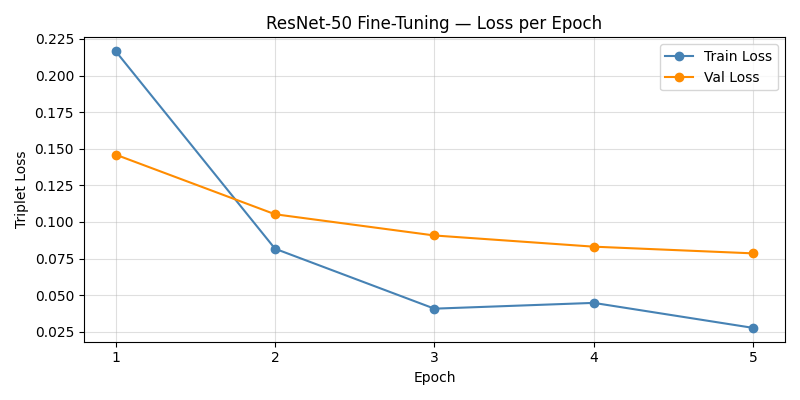

In [9]:
# Display saved loss curve for ResNet-50 — reads the PNG saved during training
from IPython.display import Image as IPImage, display
_png = os.path.join(MODELS_DIR, 'resnet50_loss_curve.png')
if os.path.exists(_png):
    display(IPImage(_png))
else:
    print('Loss curve PNG not found — run the training cell first.')


In [10]:
# ResNet-50 fine-tuned embeddings — load from disk (model already trained)
gallery_path_npy = os.path.join(EMBEDDINGS_DIR, "trained_resnet50_gallery.npy")
query_path_npy   = os.path.join(EMBEDDINGS_DIR, "trained_resnet50_queries.npy")

if os.path.exists(gallery_path_npy) and os.path.exists(query_path_npy):
    print("Found saved embeddings — loading from disk.")
    gallery_emb_resnet_ft = np.load(gallery_path_npy)
    query_emb_resnet_ft   = np.load(query_path_npy)
    results_resnet_ft = evaluate_recall_at_k(query_emb_resnet_ft, gallery_emb_resnet_ft)
    print("ResNet-50 Fine-Tuned Results:")
    for k, v in results_resnet_ft.items():
        print(f"  {k}: {v}")
else:
    print("Embeddings not found — run cells 10-12 first to train and extract.")
    results_resnet_ft = {}

Found saved embeddings — loading from disk.


Evaluating: 100%|██████████| 48/48 [00:24<00:00,  1.99it/s]

ResNet-50 Fine-Tuned Results:
  Recall@1: 5.94
  Recall@5: 12.41
  Recall@10: 16.42
  Recall@20: 21.51
  total_queries: 47773


---
## Section 5 — Fine-Tuning CLIP

### Why CLIP Fine-Tuning is Different

CLIP has two encoders — image and text — trained together. We only fine-tune the **image encoder** on fashion triplets. The text encoder stays frozen so text search still works.

```
CLIP image encoder  ← fine-tune on consumer-shop triplets
CLIP text encoder   ← freeze (preserve text search capability)
```

CLIP was trained with **contrastive loss** (matching image+text pairs). We switch to **triplet loss** for fine-tuning because our training signal is image-image pairs (consumer ↔ shop), not image-text pairs.

### Freeze Strategy for CLIP

CLIP's ViT image encoder has 12 transformer blocks. We freeze the first 9 and train only the last 3 — these deeper layers encode higher-level semantics that need fashion-specific adjustment.

In [11]:
from transformers import CLIPModel, CLIPProcessor

clip_model     = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model.to(DEVICE)

# Freeze text encoder entirely
for param in clip_model.text_model.parameters():
    param.requires_grad = False

# Freeze first 9 of 12 vision transformer blocks
for i, block in enumerate(clip_model.vision_model.encoder.layers):
    if i < 9:
        for param in block.parameters():
            param.requires_grad = False

trainable = sum(p.numel() for p in clip_model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in clip_model.parameters())
print(f"Trainable parameters: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")

/Users/anushrin/Documents/AG/ShopAssist/StyleLense/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 56687.48it/s]


Trainable parameters: 24,320,513 / 151,277,313 (16.1%)


In [ ]:
import os

best_model_path = os.path.join(MODELS_DIR, "clip_best.pth")
if os.path.exists(best_model_path):
    print("✅ Found fine-tuned CLIP weights. Skipping training and loading weights.")
    clip_model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
else:
    EPOCHS     = 5
    BATCH_SIZE = 16    # small batch — CLIP vision encoder is large
    LR         = 5e-6
    MARGIN     = 0.3
    PATIENCE   = 2

    df_train_sub = df_train.sample(frac=0.05, random_state=42).reset_index(drop=True)
    df_val_sub   = df_val.sample(frac=0.05, random_state=42).reset_index(drop=True)
    print(f"Using {len(df_train_sub)} / {len(df_train)} training pairs (5%)")

    def clip_collate(batch):
        anchors, positives, negatives = zip(*batch)
        a = clip_processor(images=list(anchors),   return_tensors="pt", padding=True)
        p = clip_processor(images=list(positives), return_tensors="pt", padding=True)
        n = clip_processor(images=list(negatives), return_tensors="pt", padding=True)
        return a, p, n

    def _clip_embed(inputs):
        vision_out = clip_model.vision_model(pixel_values=inputs['pixel_values'])
        return clip_model.visual_projection(vision_out.pooler_output)

    clip_train_loader = DataLoader(
        CLIPTripletDataset(df_train_sub, DATASET_PATH),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=0, collate_fn=clip_collate
    )
    clip_val_loader = DataLoader(
        CLIPTripletDataset(df_val_sub, DATASET_PATH),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0, collate_fn=clip_collate
    )

    optimizer = optim.Adam(filter(lambda p: p.requires_grad, clip_model.parameters()), lr=LR)
    loss_fn   = nn.TripletMarginLoss(margin=MARGIN)

    train_losses          = []
    val_losses            = []
    best_val_loss         = float('inf')
    epochs_no_improvement = 0

    for epoch in range(EPOCHS):
        clip_model.train()
        total_train_loss = 0.0
        for a_in, p_in, n_in in tqdm(clip_train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [train]"):
            a_in = {k: v.to(DEVICE) for k, v in a_in.items()}
            p_in = {k: v.to(DEVICE) for k, v in p_in.items()}
            n_in = {k: v.to(DEVICE) for k, v in n_in.items()}
            loss = loss_fn(_clip_embed(a_in), _clip_embed(p_in), _clip_embed(n_in))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_train_loss += loss.item()

        clip_model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for a_in, p_in, n_in in tqdm(clip_val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [val]  "):
                a_in = {k: v.to(DEVICE) for k, v in a_in.items()}
                p_in = {k: v.to(DEVICE) for k, v in p_in.items()}
                n_in = {k: v.to(DEVICE) for k, v in n_in.items()}
                total_val_loss += loss_fn(_clip_embed(a_in), _clip_embed(p_in), _clip_embed(n_in)).item()

        avg_train = total_train_loss / len(clip_train_loader)
        avg_val   = total_val_loss   / len(clip_val_loader)
        train_losses.append(avg_train)
        val_losses.append(avg_val)

        epoch_dir = os.path.join(MODELS_DIR, f"clip_epoch{epoch+1}")
        clip_model.save_pretrained(epoch_dir)
        print(f"Epoch {epoch+1} — train: {avg_train:.4f} | val: {avg_val:.4f} | saved → clip_epoch{epoch+1}/", end="")

        if avg_val < best_val_loss:
            best_val_loss         = avg_val
            epochs_no_improvement = 0
            clip_model.save_pretrained(os.path.join(MODELS_DIR, "clip_best"))
            print("  ← best", end="")
        else:
            epochs_no_improvement += 1
            print(f"  (no improvement {epochs_no_improvement}/{PATIENCE})", end="")
        print()

        if epochs_no_improvement >= PATIENCE:
            print(f"Early stopping triggered after {PATIENCE} epochs without improvement.")
            break

    print(f"\nBest val loss: {best_val_loss:.4f} — clip_best/")

    actual_epochs = len(train_losses)
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, actual_epochs+1), train_losses, marker='o', label='Train Loss', color='steelblue')
    plt.plot(range(1, actual_epochs+1), val_losses,   marker='o', label='Val Loss',   color='darkorange')
    plt.xlabel('Epoch'); plt.ylabel('Triplet Loss')
    plt.title('CLIP ViT-B/32 Fine-Tuning — Loss per Epoch')
    plt.xticks(range(1, actual_epochs+1)); plt.legend(); plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(MODELS_DIR, "clip_loss_curve.png"))
    plt.show()


Using 4942 / 98832 training pairs (5%)


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.61it/s]


Epoch 1 — train: 0.0634 | val: 0.0405 | saved → clip_epoch1/

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.51it/s]


  ← best


Epoch 2/5 [train]:  79%|███████▉  | 245/309 [02:48<00:43,  1.47it/s]

In [ ]:
# Display saved loss curve for CLIP ViT-B/32 — reads the PNG saved during training
from IPython.display import Image as IPImage, display
_png = os.path.join(MODELS_DIR, 'clip_loss_curve.png')
if os.path.exists(_png):
    display(IPImage(_png))
else:
    print('Loss curve PNG not found — run the training cell first.')


---
## Section 6 — Fine-Tuning EfficientNet-B4

### Why EfficientNet-B4 Fine-Tuning is Interesting

EfficientNet-B4 was the **best baseline** in `model_experiments.ipynb` (Recall@1: 3.89 vs ResNet-50: 3.08). It uses higher-resolution input (380×380 vs 224×224), allowing it to capture fine-grained texture details — critical for fashion where fabric pattern and stitching matter.

### Architecture Recap

EfficientNet uses **compound scaling** — instead of just making the network deeper (more layers) or wider (more channels), it scales depth, width, and resolution together by a fixed ratio. B4 is 4 steps up from the baseline B0.

```
Input: 380×380 image
  → MBConv blocks (mobile inverted bottleneck convolutions)
  → AdaptiveAvgPool → Flatten
  → 1792-dim embedding
```

### Freeze Strategy

EfficientNet has 9 main feature blocks (`features[0]` through `features[8]`). We freeze the first 5 (low-level edges, textures) and train the last 4 (high-level semantic features that need fashion adaptation).

| Frozen (0–4) | Trainable (5–8) |
|---|---|
| Low-level: edges, colors, basic textures | High-level: part shapes, material patterns, style |

### Key Difference from ResNet-50

EfficientNet's `features` attribute is a `nn.Sequential` of 9 blocks — we iterate over it directly. ResNet uses named layers (`layer1`–`layer4`). Same principle, different API.

In [ ]:
from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights

# EfficientNet-B4 uses 380×380 input
efficientnet_transform = transforms.Compose([
    transforms.Resize(384),
    transforms.CenterCrop(380),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Load backbone — remove classifier head, keep 1792-dim pool output
effnet_ft = efficientnet_b4(weights=EfficientNet_B4_Weights.IMAGENET1K_V1)
effnet_ft.classifier = nn.Identity()  # removes the final FC + dropout
effnet_ft.to(DEVICE)

# Freeze first 5 of 9 feature blocks (indices 0–4)
for i, block in enumerate(effnet_ft.features):
    if i < 5:
        for param in block.parameters():
            param.requires_grad = False

trainable = sum(p.numel() for p in effnet_ft.parameters() if p.requires_grad)
total     = sum(p.numel() for p in effnet_ft.parameters())
print(f"EfficientNet-B4 trainable: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")

In [ ]:
EPOCHS     = 5
BATCH_SIZE = 16   # reduced for EfficientNet-B4 (larger model, more VRAM)
LR         = 1e-4
MARGIN     = 0.3
PATIENCE   = 2

df_train_sub = df_train.sample(frac=0.05, random_state=42).reset_index(drop=True)
df_val_sub   = df_val.sample(frac=0.05, random_state=42).reset_index(drop=True)
print(f"Using {len(df_train_sub)} / {len(df_train)} training pairs (5%)")

effnet_train_loader = DataLoader(
    TripletFashionDataset(df_train_sub, DATASET_PATH, efficientnet_transform),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
effnet_val_loader = DataLoader(
    TripletFashionDataset(df_val_sub, DATASET_PATH, efficientnet_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, effnet_ft.parameters()), lr=LR)
loss_fn   = nn.TripletMarginLoss(margin=MARGIN)

train_losses          = []
val_losses            = []
best_val_loss         = float('inf')
epochs_no_improvement = 0

for epoch in range(EPOCHS):
    effnet_ft.train()
    total_train_loss = 0.0
    for anchor, positive, negative in tqdm(effnet_train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [train]"):
        anchor, positive, negative = anchor.to(DEVICE), positive.to(DEVICE), negative.to(DEVICE)
        loss = loss_fn(effnet_ft(anchor).flatten(1), effnet_ft(positive).flatten(1), effnet_ft(negative).flatten(1))
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total_train_loss += loss.item()

    effnet_ft.eval()
    total_val_loss = 0.0
    with torch.no_grad():
        for anchor, positive, negative in tqdm(effnet_val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [val]  "):
            anchor, positive, negative = anchor.to(DEVICE), positive.to(DEVICE), negative.to(DEVICE)
            total_val_loss += loss_fn(effnet_ft(anchor).flatten(1), effnet_ft(positive).flatten(1), effnet_ft(negative).flatten(1)).item()

    avg_train = total_train_loss / len(effnet_train_loader)
    avg_val   = total_val_loss   / len(effnet_val_loader)
    train_losses.append(avg_train)
    val_losses.append(avg_val)

    epoch_path = os.path.join(MODELS_DIR, f"efficientnet_b4_epoch{epoch+1}.pth")
    torch.save(effnet_ft.state_dict(), epoch_path)
    print(f"Epoch {epoch+1} — train: {avg_train:.4f} | val: {avg_val:.4f} | saved → {os.path.basename(epoch_path)}", end="")

    if avg_val < best_val_loss:
        best_val_loss         = avg_val
        epochs_no_improvement = 0
        torch.save(effnet_ft.state_dict(), os.path.join(MODELS_DIR, "efficientnet_b4_best.pth"))
        print("  ← best", end="")
    else:
        epochs_no_improvement += 1
        print(f"  (no improvement {epochs_no_improvement}/{PATIENCE})", end="")
    print()

    if epochs_no_improvement >= PATIENCE:
        print(f"Early stopping triggered after {PATIENCE} epochs without improvement.")
        break

print(f"\nBest val loss: {best_val_loss:.4f} — efficientnet_b4_best.pth")


np.save(os.path.join(MODELS_DIR, 'efficientnet_b4_train_losses.npy'), np.array(train_losses))
np.save(os.path.join(MODELS_DIR, 'efficientnet_b4_val_losses.npy'),   np.array(val_losses))
actual_epochs = len(train_losses)
plt.figure(figsize=(8, 4))
plt.plot(range(1, actual_epochs+1), train_losses, marker='o', label='Train Loss', color='steelblue')
plt.plot(range(1, actual_epochs+1), val_losses,   marker='o', label='Val Loss',   color='darkorange')
plt.xlabel('Epoch'); plt.ylabel('Triplet Loss')
plt.title('EfficientNet-B4 Fine-Tuning — Loss per Epoch')
plt.xticks(range(1, actual_epochs+1)); plt.legend(); plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, "efficientnet_b4_loss_curve.png"))
plt.show()

In [ ]:
# Display saved loss curve for EfficientNet-B4 — reads the PNG saved during training
from IPython.display import Image as IPImage, display
_png = os.path.join(MODELS_DIR, 'efficientnet_b4_loss_curve.png')
if os.path.exists(_png):
    display(IPImage(_png))
else:
    print('Loss curve PNG not found — run the training cell first.')


In [ ]:
# EfficientNet-B4 fine-tuned embeddings — load from disk (model already trained)
gallery_path_npy = os.path.join(EMBEDDINGS_DIR, "trained_efficientnet_gallery.npy")
query_path_npy   = os.path.join(EMBEDDINGS_DIR, "trained_efficientnet_queries.npy")

if os.path.exists(gallery_path_npy) and os.path.exists(query_path_npy):
    print("Found saved embeddings — loading from disk.")
    gallery_emb_effnet_ft = np.load(gallery_path_npy)
    query_emb_effnet_ft   = np.load(query_path_npy)
    results_effnet_ft = evaluate_recall_at_k(query_emb_effnet_ft, gallery_emb_effnet_ft)
    print("EfficientNet-B4 Fine-Tuned Results:")
    for k, v in results_effnet_ft.items():
        print(f"  {k}: {v}")
else:
    print("Embeddings not found — run cells 21-22 first to train and extract.")
    results_effnet_ft = {}

Found saved embeddings — loading from disk.


Evaluating: 100%|██████████| 48/48 [00:24<00:00,  1.96it/s]

EfficientNet-B4 Fine-Tuned Results:
  Recall@1: 8.18
  Recall@5: 16.61
  Recall@10: 21.46
  Recall@20: 27.3
  total_queries: 47773


---
## Section 7 — Fine-Tuning DINOv2

### Why DINOv2 Fine-Tuning is Different

DINOv2 was trained with **self-supervised learning** — no labels at all. It learned structure by predicting patches within an image (student-teacher distillation). This means it has rich structural understanding, but no fashion-specific knowledge. Fine-tuning closes that gap.

DINOv2 ViT-B/14 uses **14×14 patches** on a 224×224 input → 256 patches (vs CLIP's 49). More patches = higher spatial resolution → better at noticing small details like buttons, collar shapes, pocket placement.

### Freeze Strategy

DINOv2's ViT-B backbone has 12 transformer blocks. We freeze the first 9 (general visual structure) and fine-tune the last 3 (high-level semantics needing domain adaptation). Same ratio as CLIP.

```
12 blocks total:
  Blocks 0–8  → frozen (general structure — still useful as-is)
  Blocks 9–11 → trainable (semantic level — needs fashion tuning)
```

### Loading DINOv2

DINOv2 is loaded via `torch.hub` from Facebook Research:
```python
torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14')
```
This returns the backbone directly — no classification head to remove. Output is a 768-dim embedding from the CLS token.

### Why Lower Learning Rate Than ResNet?

ViT models are much more sensitive to large gradient steps than CNNs. The self-attention mechanism can destabilize quickly if weights change too fast. We use `lr=5e-6` (same as CLIP).

In [ ]:
# Load DINOv2 ViT-B/14 backbone
dinov2_ft = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14')
dinov2_ft.to(DEVICE)

# Freeze first 9 of 12 transformer blocks
for i, block in enumerate(dinov2_ft.blocks):
    if i < 9:
        for param in block.parameters():
            param.requires_grad = False

# Also freeze the patch embedding and positional encoding
for param in dinov2_ft.patch_embed.parameters():
    param.requires_grad = False

trainable = sum(p.numel() for p in dinov2_ft.parameters() if p.requires_grad)
total     = sum(p.numel() for p in dinov2_ft.parameters())
print(f"DINOv2 trainable: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")

NameError: name 'torch' is not defined

In [ ]:
import os

best_model_path = os.path.join(MODELS_DIR, "dinov2_best.pth")
if os.path.exists(best_model_path):
    print("✅ Found fine-tuned DINOv2 weights. Skipping training and loading weights.")
    dinov2_ft.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
else:
    EPOCHS     = 5
    BATCH_SIZE = 16   # reduced for DINOv2 (larger model, more VRAM)
    LR         = 5e-6
    MARGIN     = 0.3
    PATIENCE   = 2

    df_train_sub = df_train.sample(frac=0.05, random_state=42).reset_index(drop=True)
    df_val_sub   = df_val.sample(frac=0.05, random_state=42).reset_index(drop=True)
    print(f"Using {len(df_train_sub)} / {len(df_train)} training pairs (5%)")

    dinov2_train_loader = DataLoader(
        CachedTripletFashionDataset(df_train_sub, DATASET_PATH, imagenet_transform),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    dinov2_val_loader = DataLoader(
        CachedTripletFashionDataset(df_val_sub, DATASET_PATH, imagenet_transform),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )

    optimizer = optim.Adam(filter(lambda p: p.requires_grad, dinov2_ft.parameters()), lr=LR)
    loss_fn   = nn.TripletMarginLoss(margin=MARGIN)

    train_losses          = []
    val_losses            = []
    best_val_loss         = float('inf')
    epochs_no_improvement = 0

    for epoch in range(EPOCHS):
        dinov2_ft.train()
        total_train_loss = 0.0
        for anchor, positive, negative in tqdm(dinov2_train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [train]"):
            anchor, positive, negative = anchor.to(DEVICE), positive.to(DEVICE), negative.to(DEVICE)
            loss = loss_fn(dinov2_ft(anchor), dinov2_ft(positive), dinov2_ft(negative))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_train_loss += loss.item()

        dinov2_ft.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for anchor, positive, negative in tqdm(dinov2_val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [val]  "):
                anchor, positive, negative = anchor.to(DEVICE), positive.to(DEVICE), negative.to(DEVICE)
                total_val_loss += loss_fn(dinov2_ft(anchor), dinov2_ft(positive), dinov2_ft(negative)).item()

        avg_train = total_train_loss / len(dinov2_train_loader)
        avg_val   = total_val_loss   / len(dinov2_val_loader)
        train_losses.append(avg_train)
        val_losses.append(avg_val)

        epoch_path = os.path.join(MODELS_DIR, f"dinov2_epoch{epoch+1}.pth")
        torch.save(dinov2_ft.state_dict(), epoch_path)
        print(f"Epoch {epoch+1} — train: {avg_train:.4f} | val: {avg_val:.4f} | saved → {os.path.basename(epoch_path)}", end="")

        if avg_val < best_val_loss:
            best_val_loss         = avg_val
            epochs_no_improvement = 0
            torch.save(dinov2_ft.state_dict(), os.path.join(MODELS_DIR, "dinov2_best.pth"))
            print("  ← best", end="")
        else:
            epochs_no_improvement += 1
            print(f"  (no improvement {epochs_no_improvement}/{PATIENCE})", end="")
        print()

        if epochs_no_improvement >= PATIENCE:
            print(f"Early stopping triggered after {PATIENCE} epochs without improvement.")
            break

    print(f"\nBest val loss: {best_val_loss:.4f} — dinov2_best.pth")


    np.save(os.path.join(MODELS_DIR, 'dinov2_train_losses.npy'), np.array(train_losses))
    np.save(os.path.join(MODELS_DIR, 'dinov2_val_losses.npy'),   np.array(val_losses))
    actual_epochs = len(train_losses)
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, actual_epochs+1), train_losses, marker='o', label='Train Loss', color='steelblue')
    plt.plot(range(1, actual_epochs+1), val_losses,   marker='o', label='Val Loss',   color='darkorange')
    plt.xlabel('Epoch'); plt.ylabel('Triplet Loss')
    plt.title('DINOv2 ViT-B/14 Fine-Tuning — Loss per Epoch')
    plt.xticks(range(1, actual_epochs+1)); plt.legend(); plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(MODELS_DIR, "dinov2_loss_curve.png"))
    plt.show()


In [ ]:
# Display saved loss curve for DINOv2 ViT-B/14 — reads the PNG saved during training
from IPython.display import Image as IPImage, display
_png = os.path.join(MODELS_DIR, 'dinov2_loss_curve.png')
if os.path.exists(_png):
    display(IPImage(_png))
else:
    print('Loss curve PNG not found — run the training cell first.')


In [ ]:
# Evaluate fine-tuned DINOv2
dinov2_ft.eval()

def extract_dinov2_embeddings_ft(image_paths, batch_size=64, desc="DINOv2-FT"):
    all_embeddings = []
    dataset = FashionDataset(image_paths, DATASET_PATH, imagenet_transform)
    loader  = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    with torch.no_grad():
        for imgs, idxs in tqdm(loader, desc=desc):
            feats = dinov2_ft(imgs.to(DEVICE)).cpu().numpy()
            norms = np.linalg.norm(feats, axis=1, keepdims=True)
            all_embeddings.append(feats / np.maximum(norms, 1e-8))
    embeddings = np.zeros((len(image_paths), all_embeddings[0].shape[1]), dtype=np.float32)
    offset = 0
    for batch in all_embeddings:
        embeddings[offset:offset+len(batch)] = batch
        offset += len(batch)
    return embeddings

gallery_path_npy = os.path.join(EMBEDDINGS_DIR, "trained_dinov2_gallery.npy")
query_path_npy   = os.path.join(EMBEDDINGS_DIR, "trained_dinov2_queries.npy")

if os.path.exists(gallery_path_npy) and os.path.exists(query_path_npy):
    print("Found saved embeddings — loading from disk.")
    gallery_emb_dinov2_ft = np.load(gallery_path_npy)
    query_emb_dinov2_ft   = np.load(query_path_npy)
else:
    print("No saved embeddings found — extracting now.")
    gallery_emb_dinov2_ft = extract_dinov2_embeddings_ft(gallery_paths, desc="DINOv2-FT Gallery")
    query_emb_dinov2_ft   = extract_dinov2_embeddings_ft(query_paths,   desc="DINOv2-FT Queries")
    np.save(gallery_path_npy, gallery_emb_dinov2_ft)
    np.save(query_path_npy,   query_emb_dinov2_ft)
    print("Embeddings saved.")

results_dinov2_ft = evaluate_recall_at_k(query_emb_dinov2_ft, gallery_emb_dinov2_ft)
print("DINOv2 Fine-Tuned Results:")
for k, v in results_dinov2_ft.items():
    print(f"  {k}: {v}")

---
## Section 8 — Before vs After Comparison (All 4 Models)

Load the baseline embeddings saved in `model_experiments.ipynb` and compare all 4 models before and after fine-tuning in a single table and chart.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load baseline embeddings from model_experiments
gallery_emb_resnet_base  = np.load(os.path.join(EMBEDDINGS_DIR, "resnet50_gallery.npy"))
query_emb_resnet_base    = np.load(os.path.join(EMBEDDINGS_DIR, "resnet50_queries.npy"))
gallery_emb_effnet_base  = np.load(os.path.join(EMBEDDINGS_DIR, "efficientnet_gallery.npy"))
query_emb_effnet_base    = np.load(os.path.join(EMBEDDINGS_DIR, "efficientnet_queries.npy"))
gallery_emb_clip_base    = np.load(os.path.join(EMBEDDINGS_DIR, "clip_gallery.npy"))
query_emb_clip_base      = np.load(os.path.join(EMBEDDINGS_DIR, "clip_queries.npy"))
gallery_emb_dinov2_base  = np.load(os.path.join(EMBEDDINGS_DIR, "dinov2_gallery.npy"))
query_emb_dinov2_base    = np.load(os.path.join(EMBEDDINGS_DIR, "dinov2_queries.npy"))

print("Evaluating baselines...")
results_resnet_base  = evaluate_recall_at_k(query_emb_resnet_base,  gallery_emb_resnet_base)
results_effnet_base  = evaluate_recall_at_k(query_emb_effnet_base,  gallery_emb_effnet_base)
results_clip_base    = evaluate_recall_at_k(query_emb_clip_base,    gallery_emb_clip_base)
results_dinov2_base  = evaluate_recall_at_k(query_emb_dinov2_base,  gallery_emb_dinov2_base)

def row(name, results):
    return {'Model': name, **{k: v for k, v in results.items() if k != 'total_queries'}}

# Only include fine-tuned rows where results are available (skipped models are excluded)
_g = globals()
all_rows = [
    row('ResNet-50 (baseline)',         results_resnet_base),
]
if _g.get('results_resnet_ft'):
    all_rows.append(row('ResNet-50 (fine-tuned)', results_resnet_ft))

all_rows.append(row('EfficientNet-B4 (baseline)', results_effnet_base))
if _g.get('results_effnet_ft'):
    all_rows.append(row('EfficientNet-B4 (fine-tuned)', results_effnet_ft))

all_rows.append(row('CLIP ViT-B/32 (baseline)', results_clip_base))
if _g.get('results_clip_ft'):
    all_rows.append(row('CLIP ViT-B/32 (fine-tuned)', results_clip_ft))

all_rows.append(row('DINOv2 ViT-B/14 (baseline)', results_dinov2_base))
if _g.get('results_dinov2_ft'):
    all_rows.append(row('DINOv2 ViT-B/14 (fine-tuned)', results_dinov2_ft))

comparison = pd.DataFrame(all_rows)
print("\n=== Comparison (fine-tuned rows shown only if training was run) ===")
print(comparison.to_string(index=False))

# Bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.cm.tab10.colors

for ax, metric in zip(axes, ['Recall@1', 'Recall@10']):
    x = np.arange(len(comparison))
    ax.bar(x, comparison[metric].values, color=colors[:len(comparison)], alpha=0.85)
    ax.set_title(f'{metric}')
    ax.set_xticks(x)
    ax.set_xticklabels(comparison['Model'].values, rotation=20, ha='right', fontsize=8)
    ax.set_ylabel('Recall (%)')

plt.tight_layout()
plt.show()

### My Analysis — What Fine-Tuning Changed

*(Fill in after running — answer in first person)*

**For each model, how much did Recall@1 improve after fine-tuning?**
- ResNet-50: baseline → fine-tuned → improvement = ?
- EfficientNet-B4: baseline → fine-tuned → improvement = ?
- CLIP ViT-B/32: baseline → fine-tuned → improvement = ?
- DINOv2 ViT-B/14: baseline → fine-tuned → improvement = ?

**Which model benefited most from fine-tuning? Why?**
*(Hint: models that started lower have more room to improve. Also consider: CNNs vs ViTs — which architecture adapts faster to domain-specific data with only 5 epochs?)*

**Which fine-tuned model is the overall winner?**

**Did the triplet loss decrease steadily or plateau?**
*(What does a plateau mean? The model has learned as much as it can with the current data/hyperparameters.)*

**What would you try next to squeeze out more performance?**
- Hard negative mining (find visually similar but wrong items as negatives)
- More epochs
- Larger batch size
- Learning rate schedule (reduce LR when loss plateaus)

---
## Appendix — Related Architectures: U-Net & Keypoint Detection

> **Context:** These notes were written in reference to an **Auto Return Agent** project — a system where a customer returns an item in-store and an AI agent decides if it's eligible for return based on item condition.

---

### U-Net

Originally designed for **medical image segmentation**. Key idea: outputs a **pixel-level mask** — not "what is this image?" but "which pixels belong to which class?"

```
Input image (256×256)
     ↓  Encoder (contracting path)
  conv → pool → conv → pool → conv → pool
     ↓  Bottleneck
  conv
     ↑  Decoder (expanding path)
  upsample → conv → upsample → conv
     ↑  Skip connections (copied from encoder)
Output: segmentation mask — same spatial size as input
```

**Key innovation — skip connections:**
Decoder concatenates feature maps from the matching encoder layer, combining:
- **Where** — spatial detail from early layers
- **What** — semantic context from deep layers

Without this, upsampling loses fine spatial precision.

**In the return agent:** U-Net does damage segmentation — detects and localizes defects:
```
Stains    → red mask
Tears     → blue mask
Pilling   → green mask
Tags      → yellow mask
```
Decision rule: `defect_area / total_item_area > threshold → reject`

---

### Keypoint Detection

Finds specific landmark points on an object. Two approaches:

**Heatmap-based (most common):**
```
Input → CNN → K heatmaps (one per keypoint)
argmax of each heatmap → (x, y) coordinate
```

**Direct regression:**
```
Input → CNN → [x1, y1, x2, y2, ..., xK, yK]
```
Simpler but less accurate.

**In the return agent:** Detects structural landmarks (collar tips, sleeve ends, hem corners, buttons). Missing keypoints = structural damage. Also used to **normalize item orientation** before passing to U-Net.

---

### Full Auto Return Agent Pipeline

```
Camera captures returned item
         ↓
Keypoint detection    →  align & normalize item orientation
         ↓
Fashion retrieval     →  identify the item
(ResNet/CLIP)            (match against customer's purchase history)
         ↓
U-Net segmentation    →  detect damage regions + area
         ↓
Rule engine:
  ✓ Item identity confirmed?       (matches purchase record)
  ✓ Within return window?          (purchase date check)
  ✓ Damage area < threshold?       (U-Net output)
  ✓ Tags present?                  (keypoint / classifier)
         ↓
Decision: Accept / Reject / Escalate to human
```

**Note:** The fashion retrieval work in this capstone (feature extraction + similarity search) directly solves the **item identity** step. The return agent builds on top of it and adds the condition assessment layer.

---

### Key Challenges

| Challenge | Why it's hard |
|---|---|
| Training data | Need labeled images of damaged vs acceptable items — hard to collect |
| Lighting variability | In-store lighting is inconsistent, affects stain/damage detection |
| Fraud detection | Damage after purchase is visually identical to pre-existing damage |
| Item deformation | Folded/crumpled items look very different from flat ones — unstable keypoints |

---
## Appendix — Web Architecture Notes: Flask vs FastAPI vs Frontend

> **Context:** Notes from building the StyleLens production frontend (step5_app.py).
> Covers when to use Flask vs FastAPI, frontend choices when calling an AI agent, and what CORS is.

---

### Flask vs FastAPI — When to Use Which

**Flask (current setup):**
- Simple, synchronous, easy to reason about
- Great for serving HTML + handling model inference for a single user at a time
- Dev server blocks on each request — fine for demos, not for production traffic
- Not suitable for concurrent users or long-running agent calls

**FastAPI:**
- Built on `asyncio` — handles many requests concurrently without blocking
- Native `StreamingResponse` — agent can stream tokens back word by word
- WebSocket support — real-time back-and-forth conversation
- Auto-generated `/docs` (Swagger UI) for free
- Every route needs `async def`; PyTorch inference must be offloaded to avoid blocking:
  ```python
  await loop.run_in_executor(None, embed_image, img)
  ```
- Request/response bodies need Pydantic type models (more boilerplate upfront)
- Different startup: `uvicorn step5_app:app --reload`

**Rule of thumb:**

| Scenario | Right Choice |
|---|---|
| Demo / single user | Flask |
| Agent with single response | Flask with longer timeout, or FastAPI |
| Agent with streaming output | FastAPI + StreamingResponse (SSE) |
| Conversational chat agent | FastAPI + WebSocket |

---

### Frontend Choice When Calling an Agent

**Plain HTML + `fetch()`**  
Right for: query → single agent response. Simple, no build tooling.

**Plain HTML + `EventSource` (SSE)**  
Right for: streaming agent response — agent types back word by word.  
~20 lines of vanilla JS, no framework needed.

**React / Vue**  
Right for: multi-turn chat with history, tool call results shown inline, intermediate agent steps visualized live.  
Adds npm + webpack/vite build step — only worth it when state complexity outgrows vanilla JS.

For this capstone: current HTML frontend is correct for fashion search.  
If adding an agent layer → migrate to FastAPI + keep HTML (add SSE if streaming).  
React only if building a full chat interface with visible reasoning steps.

---

### CORS — What It Is and When It Matters

CORS (Cross-Origin Resource Sharing) is a browser security rule: JavaScript on page A cannot call an API on server B unless server B explicitly allows it via a response header:

```
Access-Control-Allow-Origin: *
```

`flask_cors` adds this header automatically to every Flask response.

Not strictly needed when frontend and backend share the same Flask origin.  
Required if you split them — e.g. React dev server on `:3000` calling Flask API on `:5000`.
